In [2]:
import pandas as pd
import numpy as np

df=pd.read_excel(r"D:\Game\F1\merged\masterfile.xlsx")

5.1 Data Overview

In [44]:
print('The number of Races in the dataset is:', df['Race Name'].count())


The number of Races in the dataset is: 27480


In [45]:
print('The number of Seasons in the dataset is:', df['Season'].nunique())

The number of Seasons in the dataset is: 77


In [46]:
print('The number of Circuits in the dataset is:', df['Circuit Name'].nunique())

The number of Circuits in the dataset is: 77


In [47]:
print('The number of Drivers in the dataset is:', df['Driver Name'].nunique())

The number of Drivers in the dataset is: 865


In [49]:
print('The number of Constructors Teams in the dataset is:', df['Constructor'].nunique())

The number of Constructors Teams in the dataset is: 213


In [ ]:
df.fillna(0, inplace=True)

In [18]:
df.isnull().sum()


Season                 0
Race Name              0
Race Date              0
Circuit Name           0
Country                0
Driver Name            0
Nationality            0
Constructor            0
Grid Position          0
Finish Position        0
Points                 0
Fastest Lap            0
Number Of Pit-Stops    0
Status                 0
Laps                   0
Race Time              0
resultId               0
raceId                 0
driverId               0
constructorId          0
number                 0
position               0
positionText           0
milliseconds           0
fastestLapTime         0
fastestLapSpeed        0
statusId               0
circuitId              0
dtype: int64

In [ ]:
numerical_features = df.select_dtypes(include=[np.number])
categorical_features = df.select_dtypes(include=['object'])

In [50]:
print('the numerical columns in the dataset are:')
numerical_features

the numerical columns in the dataset are:


,Season,Race Name,Finish Position,Points,Number Of Pit-Stops,Laps,resultId,raceId,driverId,constructorId,milliseconds,statusId,circuitId
0,2026,27480,1,25.0,3,70,27464,1179,846,1,5996180.0,1,11
1,2026,27480,2,18.0,2,70,27465,1179,830,9,6011260.0,1,11
2,2026,27480,3,15.0,2,70,27466,1179,863,131,6014908.0,1,11
3,2026,27480,4,12.0,3,70,27467,1179,844,6,6020020.0,1,11
4,2026,27480,5,10.0,3,70,27468,1179,1,6,6020720.0,1,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...
27475,1950,27480,19,0.0,0,8,20043,833,789,154,0.0,51,9
27476,1950,27480,20,0.0,0,5,20044,833,661,151,0.0,6,9
27477,1950,27480,21,0.0,0,2,20045,833,790,151,0.0,126,9
27478,1950,27480,10,0.0,0,64,20177,833,788,105,0.0,16,9


In [52]:
print('the alphabetical columns in the dataset are:')
categorical_features

the alphabetical columns in the dataset are:


,Circuit Name,Country,Driver Name,Nationality,Constructor,Grid Position,Fastest Lap,Status,Race Time,number,position,positionText,fastestLapTime,fastestLapSpeed
0,Hungaroring,Hungary,Lando Norris,British,McLaren,1,64,Finished,00:39:56.200000,1,1,1,00:01:22.500000,\N
1,Hungaroring,Hungary,Max Verstappen,Dutch,Red Bull,4,66,Finished,15.08,3,2,2,00:01:23.400000,\N
2,Hungaroring,Hungary,Andrea Kimi Antonelli,Italian,Mercedes,7,58,Finished,18.728,12,3,3,00:01:22.400000,\N
3,Hungaroring,Hungary,Charles Leclerc,Monegasque,Ferrari,2,58,Finished,23.84,16,4,4,00:01:22,\N
4,Hungaroring,Hungary,Lewis Hamilton,British,Ferrari,5,59,Finished,24.54,44,5,5,00:01:22.300000,\N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27475,Silverstone Circuit,UK,EugÃ¨ne Martin,French,Talbot-Lago,7,\N,Oil pressure,\N,17,\N,R,\N,\N
27476,Silverstone Circuit,UK,Peter Walker,British,ERA,10,\N,Gearbox,\N,9,\N,R,\N,\N
27477,Silverstone Circuit,UK,Leslie Johnson,British,ERA,12,\N,Supercharger,\N,8,\N,R,\N,\N
27478,Silverstone Circuit,UK,Joe Fry,British,Maserati,20,\N,+6 Laps,\N,10,10,10,\N,\N


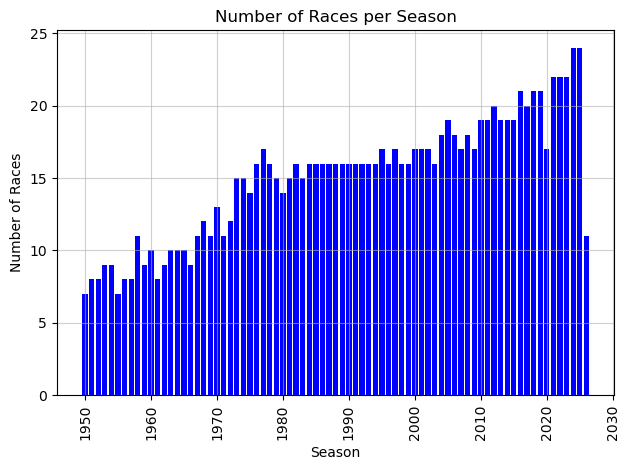

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


race_per_season=(df[['Season','raceId']].drop_duplicates()
            .groupby('Season').count())

plt.bar(race_per_season.index.astype(int),
        race_per_season['raceId'], color='blue')
        

plt.title('Number of Races per Season')
plt.xlabel('Season')
plt.ylabel('Number of Races')
plt.xticks(rotation=90)

plt.grid(True,linestyle='-', alpha=0.6)
plt.tight_layout()
plt.show()

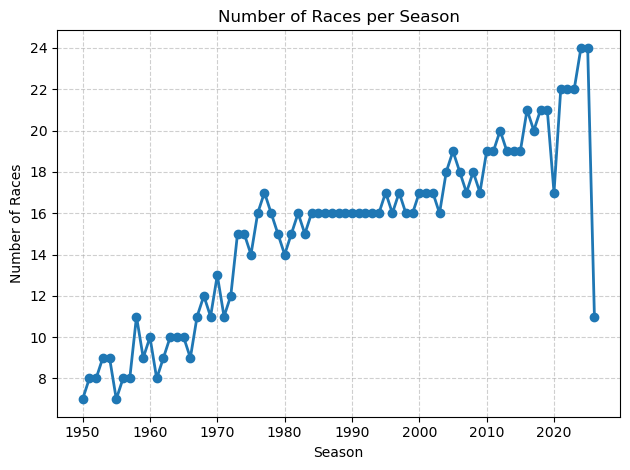

In [36]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.Figure(figsize=(15, 6))

plt.plot(
    race_per_season.index,
    race_per_season['raceId'],
    marker='o',
    linewidth=2,  
)

plt.title('Number of Races per Season')
plt.xlabel('Season')
plt.ylabel('Number of Races')

ax=plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(2))

plt.grid(True,linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

5.2 Driver Performance